# DSCI 552 — Homework 6

**Name:** Yuanda SHI  
**USC ID:** 6635-4638-05

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_score
)

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    roc_auc_score
)

from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from xgboost import XGBClassifier

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

In [2]:
PROJECT_ROOT = Path.cwd()
DATA_ROOT = PROJECT_ROOT / "data"


def find_file(filename):
    matches = list(
        DATA_ROOT.rglob(filename)
    )

    if len(matches) == 0:
        raise FileNotFoundError(
            f"Cannot find {filename} under {DATA_ROOT}"
        )

    return matches[0]


TRAIN_PATH = find_file(
    "aps_failure_training_set.csv"
)

TEST_PATH = find_file(
    "aps_failure_test_set.csv"
)

print("Training file:", TRAIN_PATH)
print("Test file:", TEST_PATH)

Training file: /Users/sydsam/Desktop/DSCI552/HW6/data/aps_failure_training_set.csv
Test file: /Users/sydsam/Desktop/DSCI552/HW6/data/aps_failure_test_set.csv


## 1. Tree-Based Methods

The APS Failure at Scania Trucks dataset is used for binary
classification.

- `pos`: failure associated with the APS system
- `neg`: failure not associated with the APS system

The original data contain 170 numerical predictors and one
binary class variable.

### 1(a) Load the APS Failure Dataset

In [3]:
train_df = pd.read_csv(
    TRAIN_PATH,
    skiprows=20,
    na_values="na"
)

test_df = pd.read_csv(
    TEST_PATH,
    skiprows=20,
    na_values="na"
)

print(
    "Training shape:",
    train_df.shape
)

print(
    "Test shape:",
    test_df.shape
)

display(
    train_df.head()
)

Training shape: (60000, 171)
Test shape: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


In [4]:
X_train_raw = (
    train_df
    .drop(columns="class")
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
)

X_test_raw = (
    test_df
    .drop(columns="class")
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
)

y_train = (
    train_df["class"]
    .map({
        "neg": 0,
        "pos": 1
    })
)

y_test = (
    test_df["class"]
    .map({
        "neg": 0,
        "pos": 1
    })
)

print(
    "Number of features:",
    X_train_raw.shape[1]
)

print(
    "\nTraining class counts:"
)

print(
    y_train.value_counts()
)

print(
    "\nTest class counts:"
)

print(
    y_test.value_counts()
)

assert X_train_raw.shape[1] == 170
assert len(X_train_raw) == 60000
assert len(X_test_raw) == 16000

Number of features: 170

Training class counts:
class
0    59000
1     1000
Name: count, dtype: int64

Test class counts:
class
0    15625
1      375
Name: count, dtype: int64


### 1(b)i Missing-Value Treatment

Common techniques for handling missing values include:

- deleting observations with missing values;
- mean imputation;
- median imputation;
- mode imputation;
- K-nearest-neighbor imputation;
- regression/model-based imputation;
- multiple imputation.

Because this dataset contains substantial missingness, deleting
all incomplete observations would discard too much information.

For this assignment, **median imputation** is used because it is
simple, robust to extreme values, and computationally efficient
for a large dataset.

For predictive modeling and cross-validation, imputation should
be learned only from the corresponding training data so that
held-out observations do not influence preprocessing.

In [5]:
missing_summary = pd.DataFrame({
    "Missing Train":
        X_train_raw.isna().sum(),

    "Missing Test":
        X_test_raw.isna().sum()
})

missing_summary[
    "Train Missing %"
] = (
    missing_summary["Missing Train"]
    / len(X_train_raw)
    * 100
)

missing_summary = (
    missing_summary
    .sort_values(
        "Train Missing %",
        ascending=False
    )
)

display(
    missing_summary.head(20)
)

print(
    "Total missing training values:",
    X_train_raw.isna().sum().sum()
)

print(
    "Total missing test values:",
    X_test_raw.isna().sum().sum()
)

,Missing Train,Missing Test,Train Missing %
br_000,49264,13129,82.106667
bq_000,48722,12981,81.203333
bp_000,47740,12721,79.566667
bo_000,46333,12376,77.221667
cr_000,46329,12363,77.215000
ab_000,46329,12363,77.215000
bn_000,44009,11713,73.348333
bm_000,39549,10546,65.915000
bl_000,27277,7226,45.461667
bk_000,23034,6094,38.390000


Total missing training values: 850015
Total missing test values: 228680


In [6]:
eda_imputer = SimpleImputer(
    strategy="median"
)

X_train_array = (
    eda_imputer.fit_transform(
        X_train_raw
    )
)

X_test_array = (
    eda_imputer.transform(
        X_test_raw
    )
)

X_train = pd.DataFrame(
    X_train_array,
    columns=X_train_raw.columns,
    index=X_train_raw.index
)

X_test = pd.DataFrame(
    X_test_array,
    columns=X_test_raw.columns,
    index=X_test_raw.index
)

print(
    "Training missing values after imputation:",
    X_train.isna().sum().sum()
)

print(
    "Test missing values after imputation:",
    X_test.isna().sum().sum()
)

Training missing values after imputation: 0
Test missing values after imputation: 0


### 1(b)ii Coefficient of Variation

For each of the 170 predictors,

\[
CV=\frac{s}{m},
\]

where \(s\) is the sample standard deviation and \(m\) is the
sample mean.

In [7]:
feature_mean = (
    X_train.mean()
)

feature_std = (
    X_train.std(
        ddof=1
    )
)

cv = (
    feature_std
    /
    feature_mean.replace(
        0,
        np.nan
    )
)

cv_table = pd.DataFrame({
    "Mean": feature_mean,
    "Sample Std": feature_std,
    "CV": cv
})

cv_table = (
    cv_table
    .sort_values(
        "CV",
        ascending=False
    )
)

display(
    cv_table
)

,Mean,Sample Std,CV
cf_000,1.431075e+05,3.504525e+07,244.887517
co_000,1.433300e+05,3.504525e+07,244.507385
ad_000,1.434383e+05,3.504525e+07,244.322816
cs_009,7.705097e+02,1.833278e+05,237.930554
dh_000,4.392641e+03,5.412441e+05,123.216097
...,...,...,...
bo_000,3.258947e+05,2.582334e+05,0.792383
bp_000,3.420739e+05,2.577156e+05,0.753392
bq_000,3.573117e+05,2.567407e+05,0.718534
br_000,3.713041e+05,2.558701e+05,0.689112


### 1(b)iii Correlation Matrix

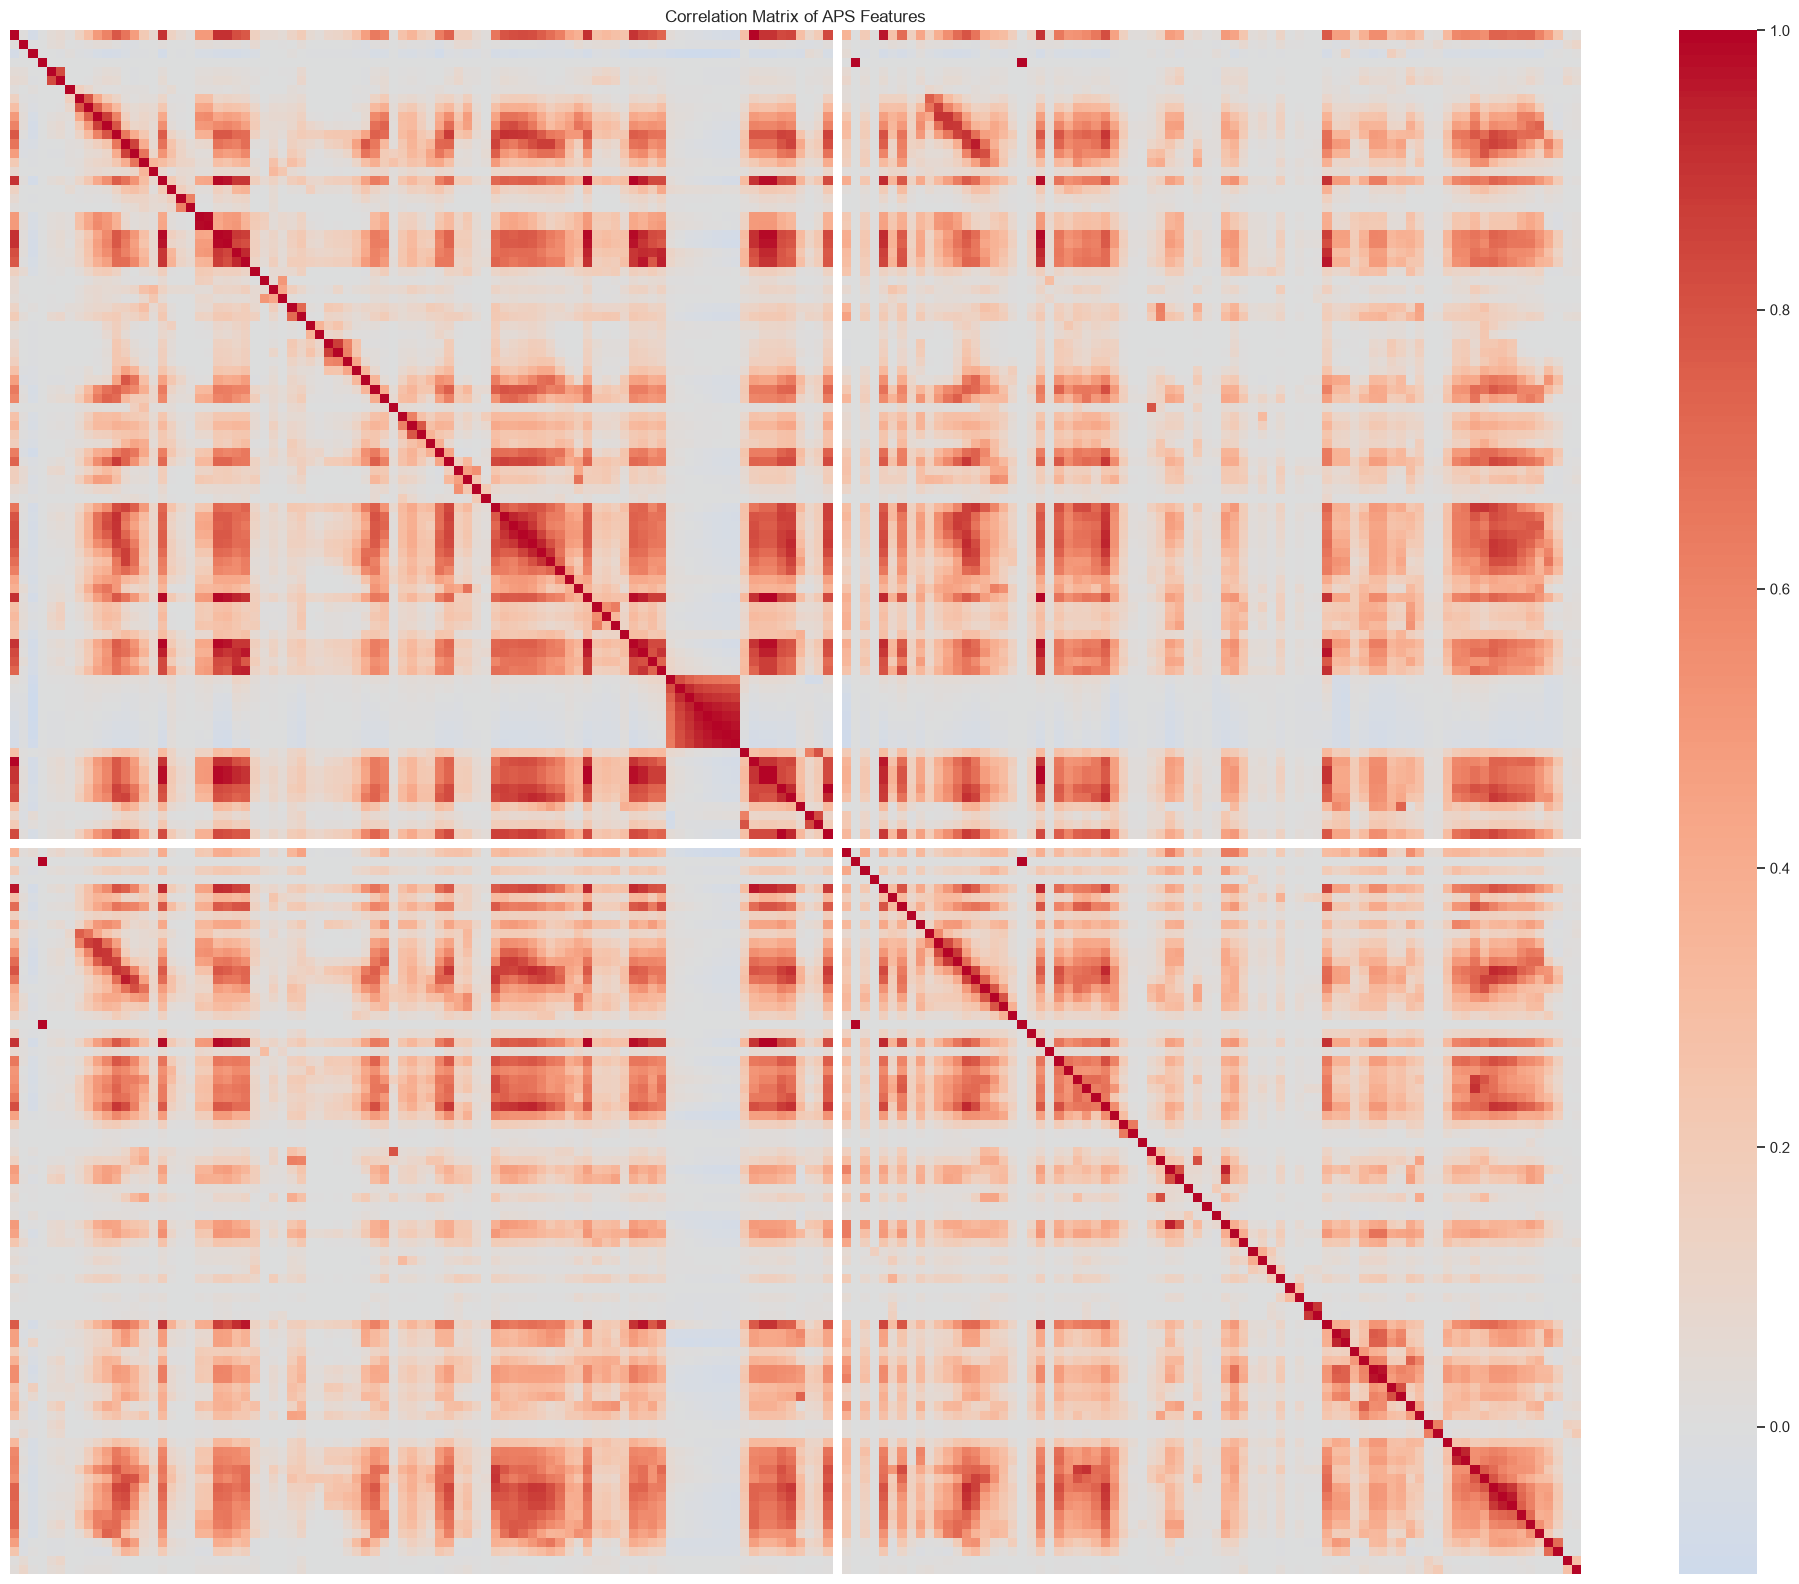

In [8]:
correlation_matrix = (
    X_train.corr()
)

plt.figure(
    figsize=(20, 16)
)

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title(
    "Correlation Matrix of APS Features"
)

plt.tight_layout()
plt.show()

### 1(b)iv Features with the Largest CV

Since there are 170 predictors,

\[
\left\lfloor\sqrt{170}\right\rfloor=13.
\]

The 13 predictors with the largest coefficients of variation are
selected **only for visualization**. All 170 predictors will still
be used in the subsequent classification models.

In [9]:
N_TOP = int(
    np.floor(
        np.sqrt(170)
    )
)

top_cv_features = (
    cv_table
    .dropna(
        subset=["CV"]
    )
    .head(N_TOP)
    .index
    .tolist()
)

print(
    "Number of selected features:",
    N_TOP
)

print(
    "\nTop CV features:"
)

for feature in top_cv_features:
    print(feature)

display(
    cv_table.loc[
        top_cv_features
    ]
)

Number of selected features: 13

Top CV features:
cf_000
co_000
ad_000
cs_009
dh_000
dj_000
ag_000
as_000
ay_009
ak_000
az_009
ch_000
au_000


,Mean,Sample Std,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


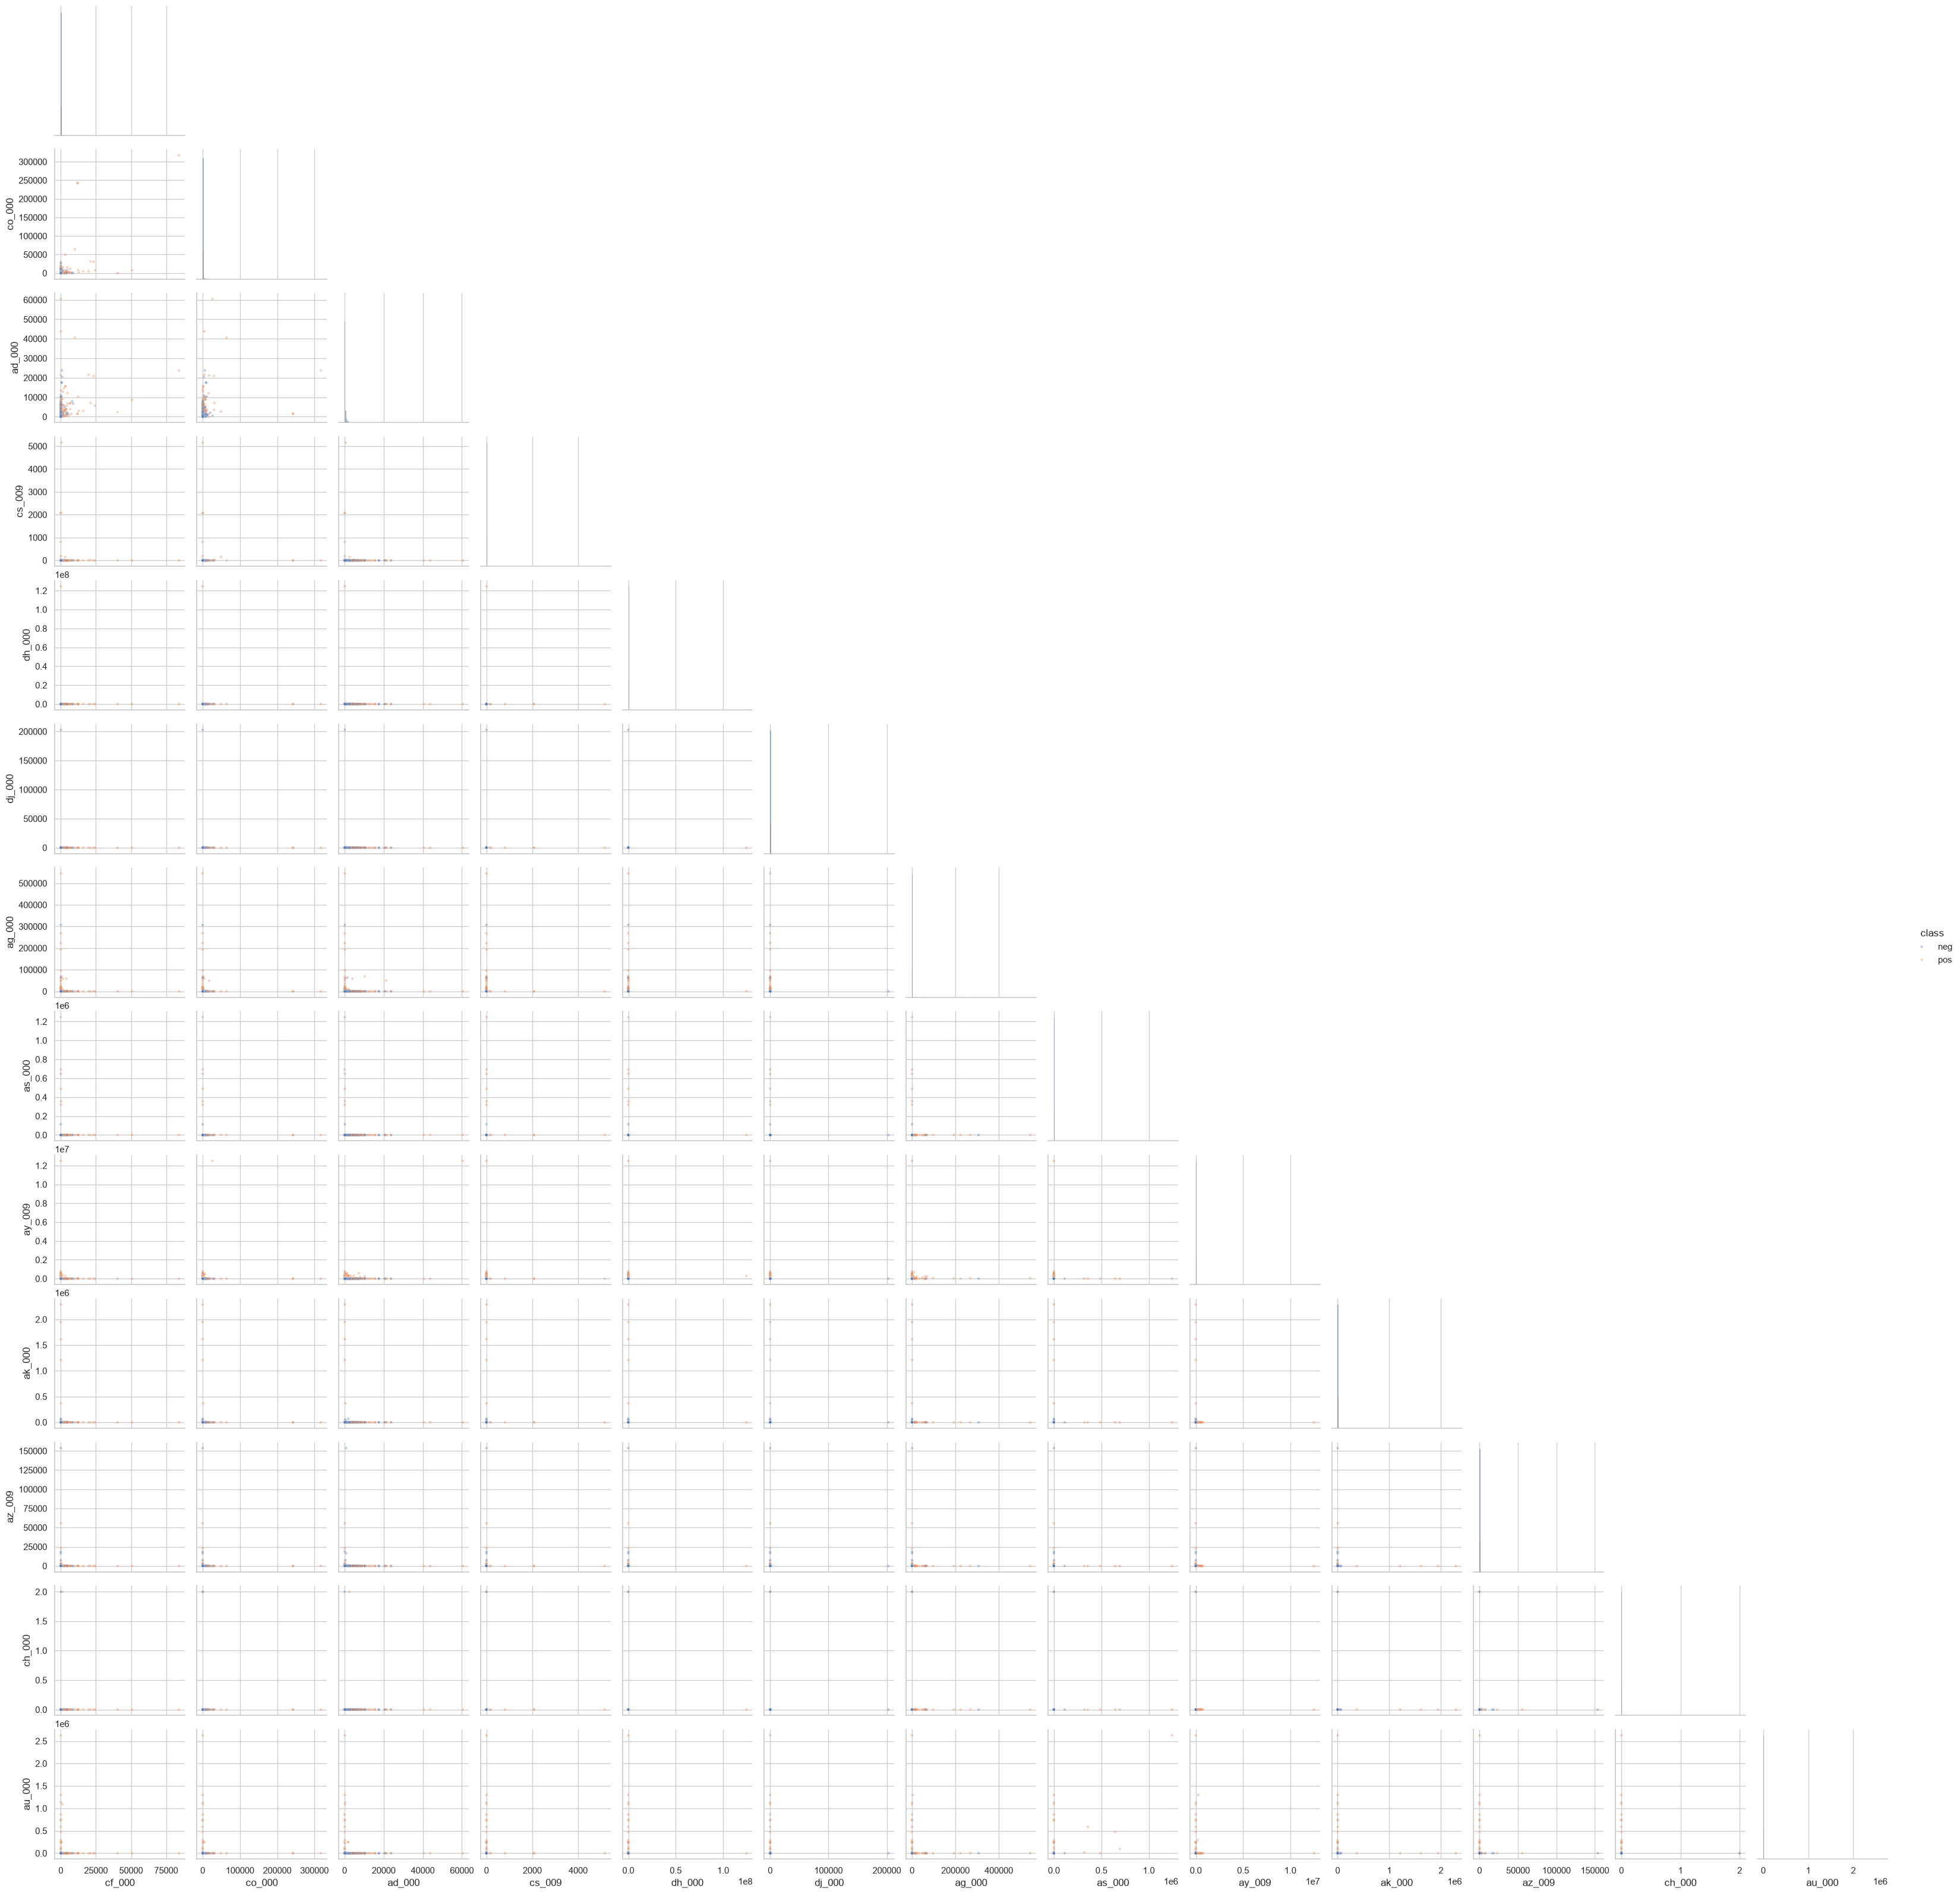

In [11]:
#60,000 data entries, each consisting of a 13×13 grid, would be extremely heavy to process; therefore, for visualization purposes, we use all positive samples plus a random subset of negative samples, while the full training set is still used for the model itself.
positive_indices = (
    y_train[
        y_train == 1
    ].index
)

negative_indices = (
    y_train[
        y_train == 0
    ]
    .sample(
        n=4000,
        random_state=RANDOM_STATE
    )
    .index
)

visual_indices = (
    positive_indices
    .union(
        negative_indices
    )
)

visual_df = (
    X_train.loc[
        visual_indices,
        top_cv_features
    ]
    .copy()
)

visual_df["class"] = (
    y_train.loc[
        visual_indices
    ]
    .map({
        0: "neg",
        1: "pos"
    })
)

sns.pairplot(
    visual_df,
    hue="class",
    corner=True,
    diag_kind="hist",
    plot_kws={
        "alpha": 0.35,
        "s": 10
    }
)

plt.show()

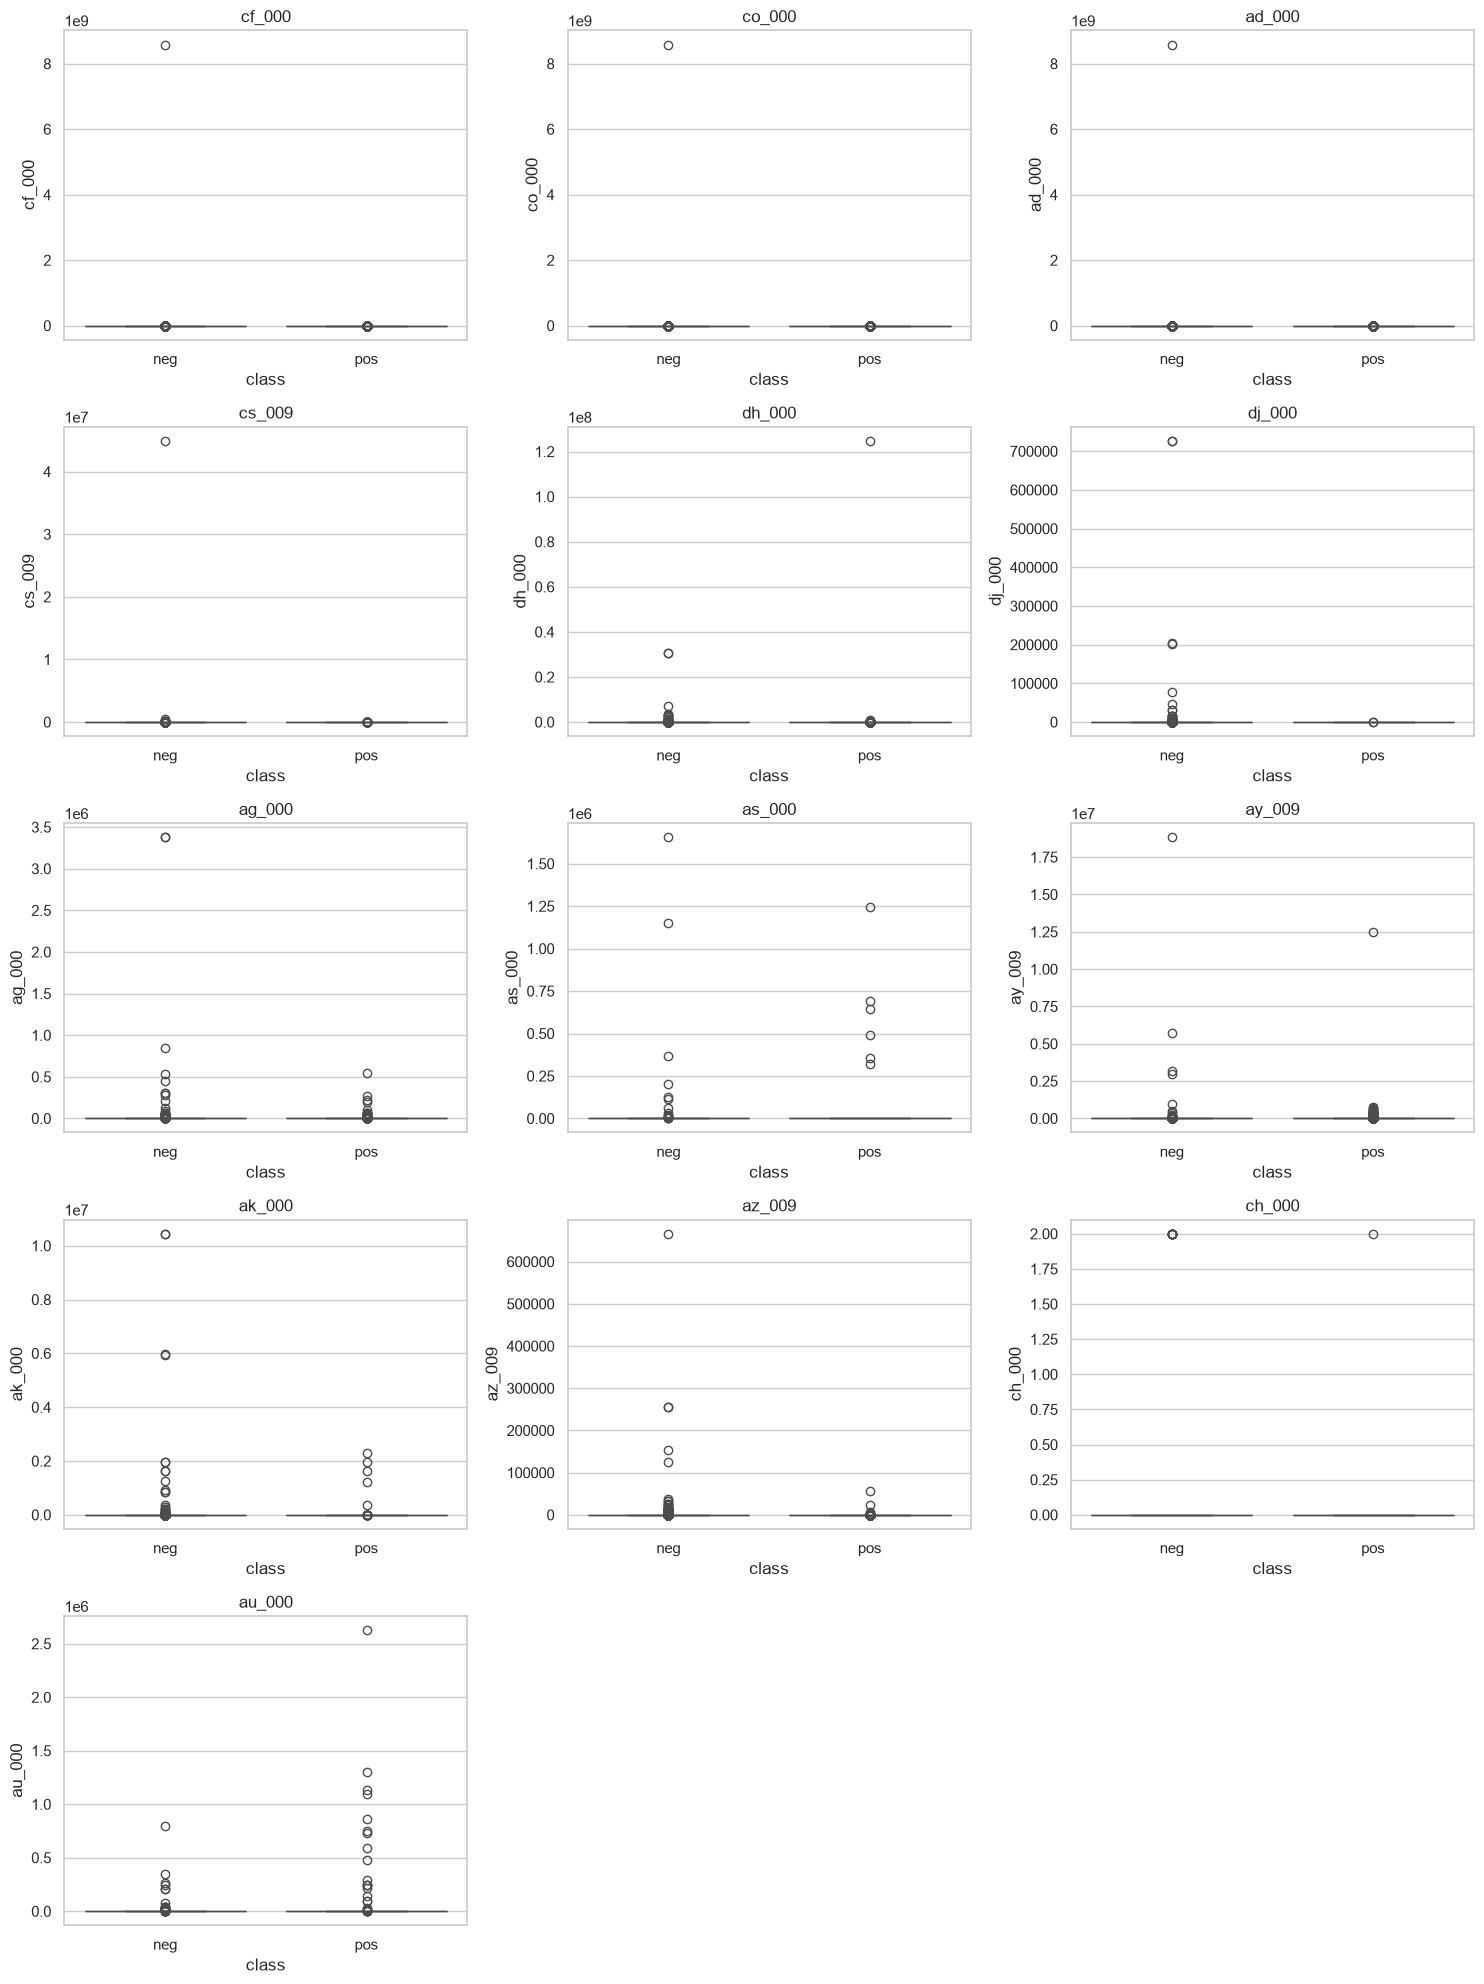

In [12]:
fig, axes = plt.subplots(
    5,
    3,
    figsize=(15, 20)
)

axes = axes.ravel()

box_df = (
    X_train[
        top_cv_features
    ]
    .copy()
)

box_df["class"] = (
    y_train.map({
        0: "neg",
        1: "pos"
    })
)

for i, feature in enumerate(
    top_cv_features
):

    sns.boxplot(
        data=box_df,
        x="class",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(
        feature
    )

for j in range(
    len(top_cv_features),
    len(axes)
):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### 1(b)iv Interpretation

The scatterplots and boxplots provide exploratory information about
the distributions of the high-CV features and possible differences
between the positive and negative classes.

However, **statistical significance cannot be established from these
plots alone**.

A feature may have a large coefficient of variation because of
skewness or extreme observations without necessarily being useful
for classification.

Likewise, useful predictors may not show strong separation when
examined individually because their predictive value may arise from
interactions with other variables.

Formal modeling and out-of-sample evaluation are therefore required
to determine predictive importance.

In [13]:
train_class_counts = (
    y_train
    .value_counts()
    .rename(
        index={
            0: "neg",
            1: "pos"
        }
    )
)

train_class_percent = (
    y_train
    .value_counts(
        normalize=True
    )
    .mul(100)
    .rename(
        index={
            0: "neg",
            1: "pos"
        }
    )
)

class_summary = pd.DataFrame({
    "Count": train_class_counts,
    "Percent": train_class_percent
})

display(
    class_summary
)

,Count,Percent
class,,
neg,59000,98.333333
pos,1000,1.666667


### 1(b)v Class Imbalance

The APS training data contain approximately:

- 59,000 negative observations;
- 1,000 positive observations.

Therefore, only about 1.67% of the training observations belong to
the positive class.

The dataset is consequently **severely imbalanced**.

A classifier that predicts every observation as negative would have
very high accuracy, so accuracy alone is not sufficient for evaluating
these models. Confusion matrices, ROC curves, AUC, and minority-class
errors should also be considered.



## 1(c) Random Forest Without Class-Imbalance Compensation

A random forest is first trained without any class weighting,
oversampling, or undersampling.

Out-of-bag predictions are enabled so that the OOB error estimate
can be compared with test error.

In [14]:
def evaluate_binary_classifier(
    model,
    X,
    y,
    title
):
    prediction = model.predict(X)

    probability = (
        model.predict_proba(X)[:, 1]
    )

    accuracy = accuracy_score(
        y,
        prediction
    )

    error = 1 - accuracy

    auc_value = roc_auc_score(
        y,
        probability
    )

    cm = confusion_matrix(
        y,
        prediction
    )

    print(
        f"{title} Accuracy:",
        accuracy
    )

    print(
        f"{title} Misclassification Error:",
        error
    )

    print(
        f"{title} AUC:",
        auc_value
    )

    print(
        f"\n{title} Classification Report:"
    )

    print(
        classification_report(
            y,
            prediction,
            target_names=[
                "neg",
                "pos"
            ],
            zero_division=0
        )
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "neg",
            "pos"
        ]
    ).plot()

    plt.title(
        f"{title} Confusion Matrix"
    )

    plt.show()

    fpr, tpr, _ = roc_curve(
        y,
        probability
    )

    plt.figure(
        figsize=(7, 6)
    )

    plt.plot(
        fpr,
        tpr,
        label=f"AUC = {auc_value:.4f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.title(
        f"{title} ROC Curve"
    )

    plt.legend()
    plt.grid(True)
    plt.show()

    return {
        "accuracy": accuracy,
        "error": error,
        "auc": auc_value,
        "confusion_matrix": cm
    }

In [15]:
rf_unbalanced = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),
    (
        "rf",
        RandomForestClassifier(
            n_estimators=500,
            oob_score=True,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

rf_unbalanced.fit(
    X_train_raw,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('rf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](170,)","['aa_000','ab_000','ac_000',...,'ee_009','ef_000','eg_000']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,170
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_

Unbalanced RF - Training Accuracy: 1.0
Unbalanced RF - Training Misclassification Error: 0.0
Unbalanced RF - Training AUC: 1.0

Unbalanced RF - Training Classification Report:
              precision    recall  f1-score   support

         neg       1.00      1.00      1.00     59000
         pos       1.00      1.00      1.00      1000

    accuracy                           1.00     60000
   macro avg       1.00      1.00      1.00     60000
weighted avg       1.00      1.00      1.00     60000



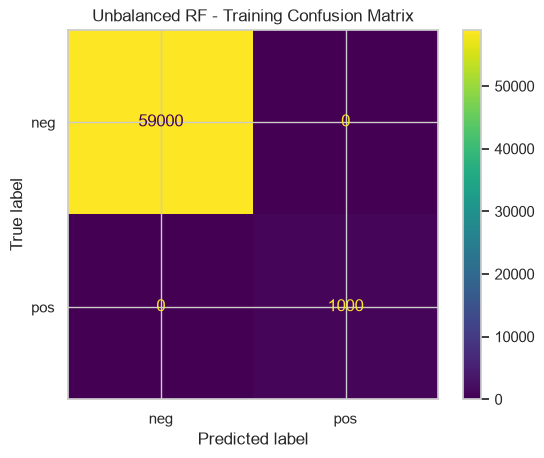

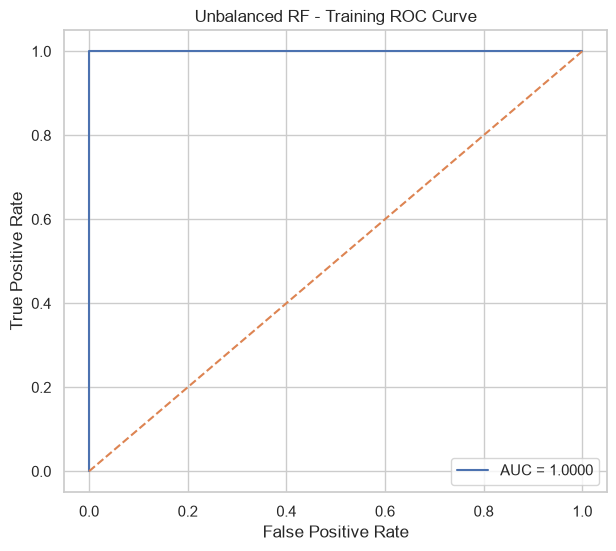

Unbalanced RF - Test Accuracy: 0.992375
Unbalanced RF - Test Misclassification Error: 0.007624999999999993
Unbalanced RF - Test AUC: 0.9943119360000001

Unbalanced RF - Test Classification Report:
              precision    recall  f1-score   support

         neg       0.99      1.00      1.00     15625
         pos       0.93      0.73      0.82       375

    accuracy                           0.99     16000
   macro avg       0.96      0.86      0.91     16000
weighted avg       0.99      0.99      0.99     16000



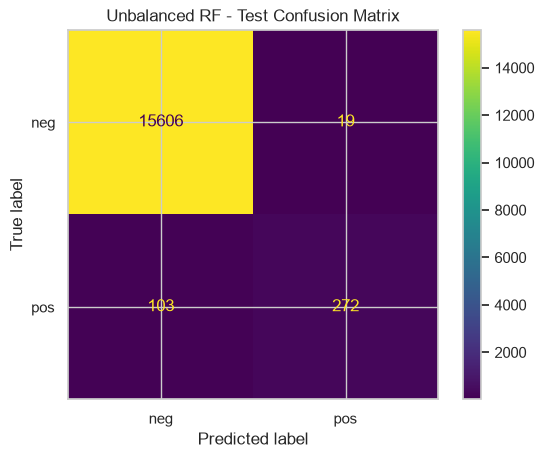

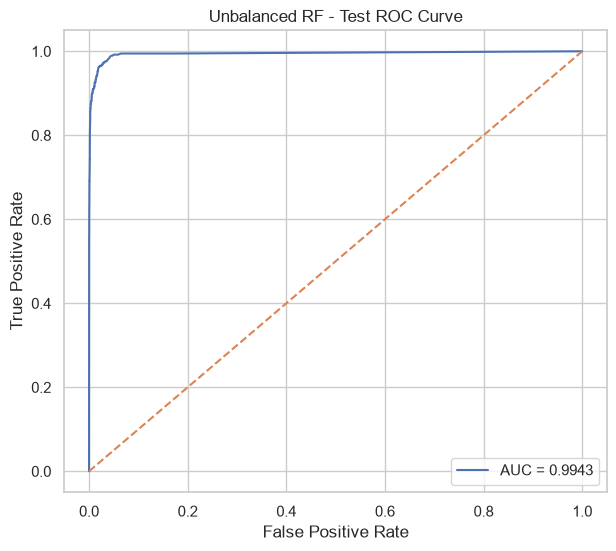

OOB accuracy: 0.9942
OOB error: 0.005800000000000027
Test error: 0.007624999999999993


In [16]:
rf_unbalanced_train = (
    evaluate_binary_classifier(
        rf_unbalanced,
        X_train_raw,
        y_train,
        "Unbalanced RF - Training"
    )
)

rf_unbalanced_test = (
    evaluate_binary_classifier(
        rf_unbalanced,
        X_test_raw,
        y_test,
        "Unbalanced RF - Test"
    )
)


rf_model_unbalanced = (
    rf_unbalanced
    .named_steps["rf"]
)

rf_oob_error = (
    1
    -
    rf_model_unbalanced.oob_score_
)

print(
    "OOB accuracy:",
    rf_model_unbalanced.oob_score_
)

print(
    "OOB error:",
    rf_oob_error
)

print(
    "Test error:",
    rf_unbalanced_test["error"]
)

### 1(c) Random Forest Without Class-Imbalance Compensation — Results

The random forest was trained using all 170 predictors without any explicit compensation for class imbalance.

### Training Performance

The model achieves:

- **Training accuracy:** 1.0000
- **Training misclassification error:** 0.0000
- **Training AUC:** 1.0000

The training confusion matrix is

\[
\begin{bmatrix}
59000 & 0 \\
0 & 1000
\end{bmatrix}.
\]

Therefore, all 59,000 negative observations and all 1,000 positive observations are correctly classified in the training data.

This indicates that the random forest is flexible enough to fit the training set perfectly.

---

### Test Performance

On the held-out test set, the model achieves:

- **Test accuracy:** 0.992375
- **Test misclassification error:** 0.007625
- **Test AUC:** 0.9943

The test confusion matrix is

\[
\begin{bmatrix}
15606 & 19 \\
103 & 272
\end{bmatrix}.
\]

Therefore:

- **15,606** negative observations are correctly classified as negative.
- **19** negative observations are incorrectly classified as positive.
- **272** positive observations are correctly classified as positive.
- **103** positive observations are incorrectly classified as negative.

For the positive APS-failure class:

\[
\text{Precision}
=
\frac{272}{272+19}
\approx 0.935,
\]

and

\[
\text{Recall}
=
\frac{272}{272+103}
\approx 0.725.
\]

Thus, although overall accuracy is very high, the classifier detects only about **72.5% of the positive APS failures**.

The positive-class F1-score is approximately **0.82**.

---

### ROC and AUC

The test ROC curve has

\[
\text{AUC}=0.9943.
\]

This indicates that the random forest has excellent overall ability to rank positive APS-failure observations above negative observations.

However, the high AUC and high overall accuracy should not hide the fact that **103 out of 375 positive test observations are missed** at the default classification threshold.

This is especially important because the dataset is severely imbalanced.

---

### Out-of-Bag Error

The random forest produces:

- **OOB accuracy:** 0.9942
- **OOB error:** 0.0058

The held-out test error is

\[
0.007625.
\]

The difference is

\[
0.007625-0.0058
=0.001825.
\]

Therefore, the OOB estimate is slightly more optimistic than the actual test error, but the two values are quite close.

This suggests that the out-of-bag error provides a reasonable estimate of the model's out-of-sample misclassification error.

---

### Interpretation of Class Imbalance

Although the random forest has a test accuracy above **99%**, this number must be interpreted carefully.

The test set contains:

\[
15625
\]

negative observations but only

\[
375
\]

positive observations.

Because the negative class is overwhelmingly more common, a model can achieve very high overall accuracy while still missing a meaningful proportion of positive cases.

In this case, the model produces only **19 false positives**, but it produces **103 false negatives**.

Therefore, the main weakness of the uncompensated random forest is its relatively low sensitivity to the minority positive class.

### Conclusion

The uncompensated random forest performs extremely well in terms of overall accuracy and ROC-AUC:

\[
\boxed{\text{Test Accuracy}=99.24\%}
\]

and

\[
\boxed{\text{Test AUC}=0.9943}.
\]

Its OOB error of **0.58%** is also close to the test error of **0.76%**, indicating that OOB error is a useful estimate of generalization performance.

However, the classifier misses **103 of the 375 positive APS failures**, giving a positive-class recall of only about **72.5%**.

Therefore, the next step is to compensate for the severe class imbalance and examine whether minority-class detection can be improved.



## 1(d) Random Forest with Class-Imbalance Compensation

Common approaches for handling class imbalance in random forests
include:

- class weighting;
- oversampling the minority class;
- undersampling the majority class;
- balanced bootstrap sampling;
- synthetic oversampling such as SMOTE;
- changing the decision threshold.

Here, `class_weight="balanced_subsample"` is used.

For each tree, class weights are automatically adjusted inversely
to the class frequencies in that tree's bootstrap sample.

In [17]:
rf_balanced = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),
    (
        "rf",
        RandomForestClassifier(
            n_estimators=500,
            class_weight="balanced_subsample",
            oob_score=True,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
])

rf_balanced.fit(
    X_train_raw,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('rf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](170,)","['aa_000','ab_000','ac_000',...,'ee_009','ef_000','eg_000']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,170
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_

Balanced RF - Training Accuracy: 1.0
Balanced RF - Training Misclassification Error: 0.0
Balanced RF - Training AUC: 1.0

Balanced RF - Training Classification Report:
              precision    recall  f1-score   support

         neg       1.00      1.00      1.00     59000
         pos       1.00      1.00      1.00      1000

    accuracy                           1.00     60000
   macro avg       1.00      1.00      1.00     60000
weighted avg       1.00      1.00      1.00     60000



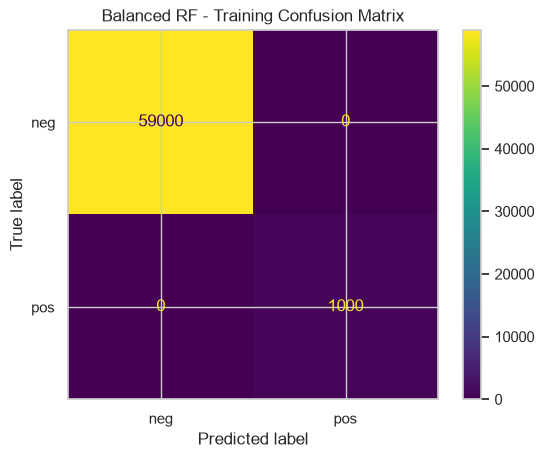

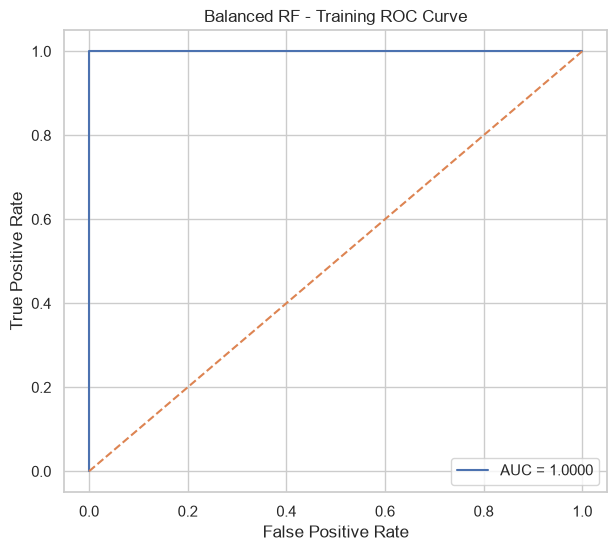

Balanced RF - Test Accuracy: 0.989125
Balanced RF - Test Misclassification Error: 0.010874999999999968
Balanced RF - Test AUC: 0.9943364266666667

Balanced RF - Test Classification Report:
              precision    recall  f1-score   support

         neg       0.99      1.00      0.99     15625
         pos       0.94      0.57      0.71       375

    accuracy                           0.99     16000
   macro avg       0.97      0.78      0.85     16000
weighted avg       0.99      0.99      0.99     16000



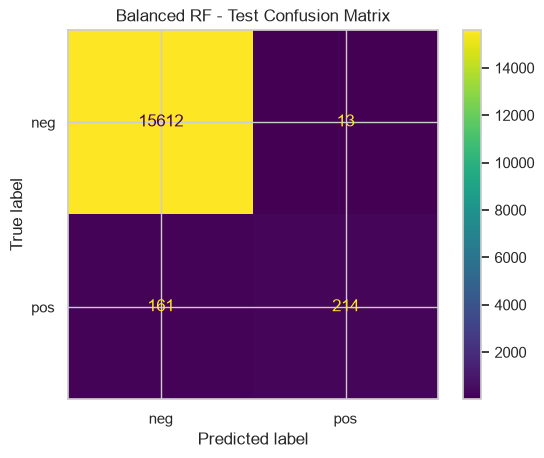

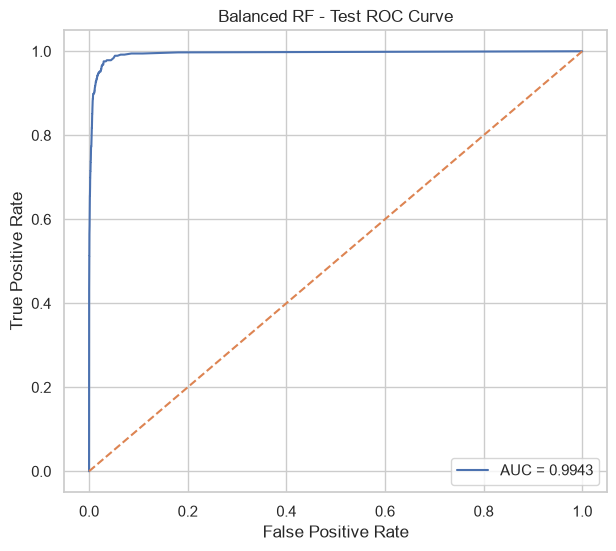

Balanced RF OOB error: 0.007533333333333281
Balanced RF test error: 0.010874999999999968


In [18]:
rf_balanced_train = (
    evaluate_binary_classifier(
        rf_balanced,
        X_train_raw,
        y_train,
        "Balanced RF - Training"
    )
)

rf_balanced_test = (
    evaluate_binary_classifier(
        rf_balanced,
        X_test_raw,
        y_test,
        "Balanced RF - Test"
    )
)

rf_model_balanced = (
    rf_balanced
    .named_steps["rf"]
)

rf_balanced_oob_error = (
    1
    -
    rf_model_balanced.oob_score_
)

print(
    "Balanced RF OOB error:",
    rf_balanced_oob_error
)

print(
    "Balanced RF test error:",
    rf_balanced_test["error"]
)

In [19]:
rf_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Balanced Random Forest"
    ],

    "Train Error": [
        rf_unbalanced_train["error"],
        rf_balanced_train["error"]
    ],

    "Test Error": [
        rf_unbalanced_test["error"],
        rf_balanced_test["error"]
    ],

    "Test AUC": [
        rf_unbalanced_test["auc"],
        rf_balanced_test["auc"]
    ],

    "OOB Error": [
        rf_oob_error,
        rf_balanced_oob_error
    ]
})

display(
    rf_comparison
)

,Model,Train Error,Test Error,Test AUC,OOB Error
0,Random Forest,0.0,0.007625,0.994312,0.005800
1,Balanced Random Forest,0.0,0.010875,0.994336,0.007533


### 1(d) Comparison of Random Forests With and Without Class-Imbalance Compensation

The uncompensated random forest and the class-balanced random forest produce the following results:

| Model | Train Error | Test Error | Test AUC | OOB Error |
|---|---:|---:|---:|---:|
| Random Forest | 0.000000 | 0.007625 | 0.994312 | 0.005800 |
| Balanced Random Forest | 0.000000 | 0.010875 | 0.994336 | 0.007533 |

### Training Performance

Both models achieve

\[
\text{Training Error}=0.
\]

Therefore, both random forests perfectly classify the training observations.

This indicates that both models are sufficiently flexible to fit the training data completely.

---

### Test Error

The uncompensated random forest has test error

\[
0.007625,
\]

while the balanced random forest has test error

\[
0.010875.
\]

Thus, the balanced model has a higher overall test misclassification rate.

The increase in test error is

\[
0.010875-0.007625
=0.00325.
\]

Therefore, based on overall test error, the original random forest performs better.

---

### ROC-AUC

The test AUC values are

\[
\text{AUC}_{\text{RF}}
= 0.994312
\]

and

\[
\text{AUC}_{\text{Balanced RF}}
= 0.994336.
\]

The balanced random forest has a slightly larger AUC, but the difference is extremely small:

\[
0.994336-0.994312
\approx
0.000024.
\]

Therefore, the two models have essentially the same overall ranking ability according to ROC-AUC.

Both AUC values are very close to 1, indicating excellent discrimination between the positive and negative classes.

---

### Out-of-Bag Error

The uncompensated model has

\[
\text{OOB Error}=0.005800,
\]

while the balanced model has

\[
\text{OOB Error}=0.007533.
\]

Thus, the balanced model also has a larger out-of-bag error.

For both models, the OOB error remains reasonably close to the corresponding test error, so the OOB estimate continues to provide a useful approximation of out-of-sample performance.

---

### Effect of Class Balancing

Using `class_weight="balanced_subsample"` changes the importance placed on the minority positive class during tree construction.

However, in this experiment, class weighting does **not** improve overall test error.

Instead:

- test error increases from **0.7625%** to **1.0875%**;
- OOB error increases from **0.5800%** to **0.7533%**;
- test AUC remains essentially unchanged at approximately **0.9943**.

Therefore, balancing the classes introduces a trade-off rather than a clear overall improvement.

It is important to note that this summary table alone does not show whether the balanced model improves positive-class recall or reduces false negatives. Those quantities should be examined using the balanced model's confusion matrix and classification report.

If minority-class recall improves while overall error increases, that would indicate that the balanced model is sacrificing some majority-class accuracy in order to detect more APS failures.

---

### Conclusion

Based on overall predictive error, the **uncompensated random forest performs better**:

\[
\boxed{
\text{Test Error}_{\text{RF}}
=
0.007625
<
0.010875
=
\text{Test Error}_{\text{Balanced RF}}
}
\]

The balanced random forest achieves only a negligible improvement in AUC:

\[
0.994312
\rightarrow
0.994336,
\]

while producing higher test and OOB errors.

Therefore, class weighting does not improve overall classification performance in this experiment. However, because the APS dataset is severely imbalanced, the final comparison should also consider the balanced model's positive-class recall and false-negative count rather than relying solely on overall error.


## 1(e) XGBoost with L1 Regularization

XGBoost is fitted without explicit compensation for class imbalance.

The L1 regularization parameter is

\[
\alpha = \text{reg\_alpha}.
\]

Five-fold stratified cross-validation is used to select the value
of \(\alpha\).

ROC-AUC is used for model selection because the response classes are
strongly imbalanced.

In [20]:
xgb_base = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",

    n_estimators=400,
    learning_rate=0.05,
    max_depth=4,

    subsample=0.8,
    colsample_bytree=0.8,

    reg_lambda=1.0,

    random_state=RANDOM_STATE,
    tree_method="hist",
    n_jobs=1
)

xgb_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),
    (
        "xgb",
        xgb_base
    )
])


alpha_grid = {
    "xgb__reg_alpha": [
        0,
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ]
}


xgb_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [21]:
xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=alpha_grid,
    cv=xgb_cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    xgb_grid.fit(
        X_train_raw,
        y_train
    )


best_xgb = (
    xgb_grid.best_estimator_
)

best_xgb_alpha = (
    xgb_grid.best_params_[
        "xgb__reg_alpha"
    ]
)

print(
    "Best alpha:",
    best_xgb_alpha
)

print(
    "Best CV ROC-AUC:",
    xgb_grid.best_score_
)

Fitting 5 folds for each of 7 candidates, totalling 35 fits
Best alpha: 1
Best CV ROC-AUC: 0.989699533898305


In [22]:
xgb_cv_accuracy = (
    cross_val_score(
        best_xgb,
        X_train_raw,
        y_train,
        cv=xgb_cv,
        scoring="accuracy",
        n_jobs=-1
    )
)

xgb_cv_error = (
    1
    -
    xgb_cv_accuracy.mean()
)

print(
    "5-fold CV accuracies:",
    xgb_cv_accuracy
)

print(
    "Mean CV accuracy:",
    xgb_cv_accuracy.mean()
)

print(
    "Estimated CV error:",
    xgb_cv_error
)

5-fold CV accuracies: [0.99533333 0.994      0.99441667 0.99416667 0.99375   ]
Mean CV accuracy: 0.9943333333333333
Estimated CV error: 0.005666666666666709


XGBoost - Training Accuracy: 0.9989166666666667
XGBoost - Training Misclassification Error: 0.001083333333333325
XGBoost - Training AUC: 0.9996750084745762

XGBoost - Training Classification Report:
              precision    recall  f1-score   support

         neg       1.00      1.00      1.00     59000
         pos       1.00      0.94      0.97      1000

    accuracy                           1.00     60000
   macro avg       1.00      0.97      0.98     60000
weighted avg       1.00      1.00      1.00     60000



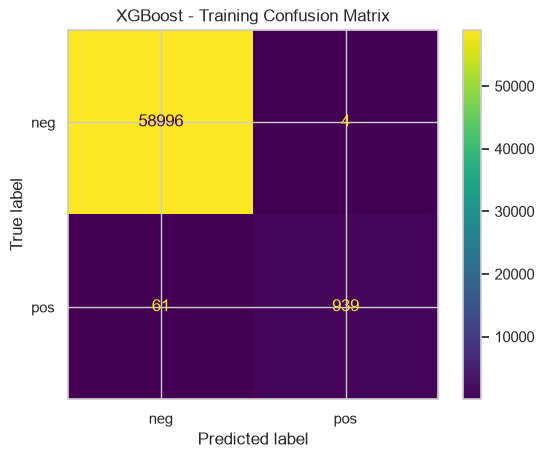

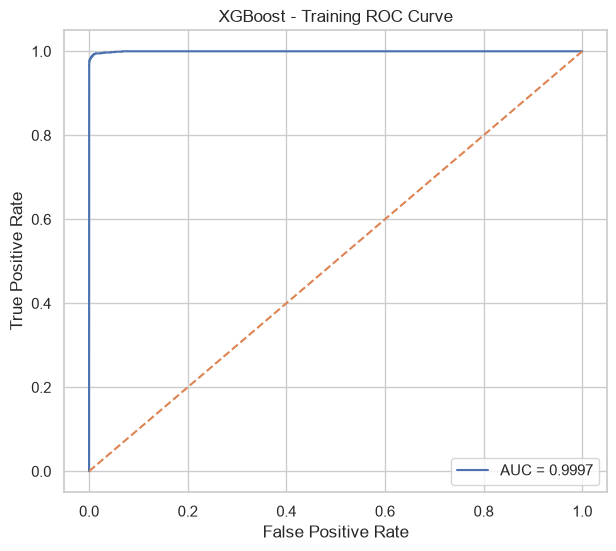

XGBoost - Test Accuracy: 0.993875
XGBoost - Test Misclassification Error: 0.006125000000000047
XGBoost - Test AUC: 0.996300288

XGBoost - Test Classification Report:
              precision    recall  f1-score   support

         neg       0.99      1.00      1.00     15625
         pos       0.96      0.77      0.86       375

    accuracy                           0.99     16000
   macro avg       0.98      0.89      0.93     16000
weighted avg       0.99      0.99      0.99     16000



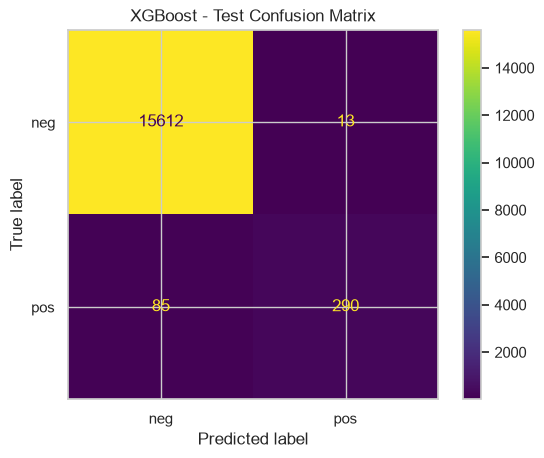

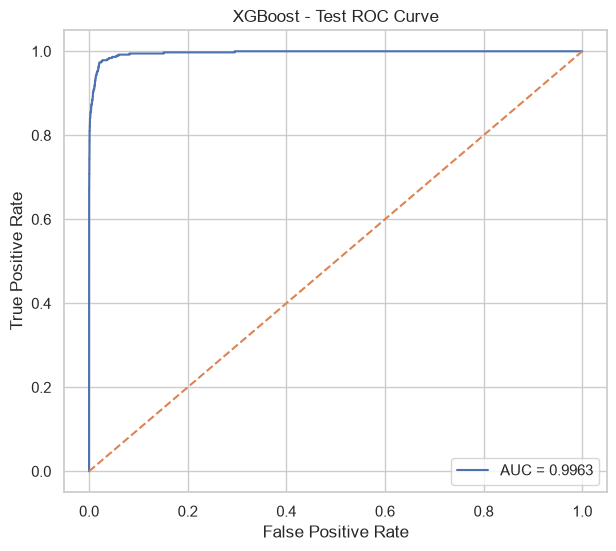

Cross-validation error: 0.005666666666666709
Test error: 0.006125000000000047


In [23]:
xgb_train_results = (
    evaluate_binary_classifier(
        best_xgb,
        X_train_raw,
        y_train,
        "XGBoost - Training"
    )
)

xgb_test_results = (
    evaluate_binary_classifier(
        best_xgb,
        X_test_raw,
        y_test,
        "XGBoost - Test"
    )
)

print(
    "Cross-validation error:",
    xgb_cv_error
)

print(
    "Test error:",
    xgb_test_results["error"]
)

### 1(e) XGBoost — Results and Interpretation

The L1-regularized XGBoost model was trained without explicit compensation for class imbalance. The regularization parameter \(\alpha\) was selected using cross-validation.

### Training Performance

The model achieves:

- **Training accuracy:** 0.998917
- **Training misclassification error:** 0.001083
- **Training AUC:** 0.999675

The training confusion matrix is

\[
\begin{bmatrix}
58996 & 4 \\
61 & 939
\end{bmatrix}.
\]

Therefore:

- 58,996 negative observations are correctly classified.
- 4 negative observations are incorrectly classified as positive.
- 939 positive observations are correctly classified.
- 61 positive observations are incorrectly classified as negative.

For the positive class, the training recall is approximately

\[
\frac{939}{1000}=0.939,
\]

so the model correctly identifies about **93.9% of the positive APS failures in the training set**.

The training AUC of approximately

\[
0.9997
\]

indicates almost perfect discrimination between the two classes.

---

### Test Performance

On the held-out test set, the model achieves:

- **Test accuracy:** 0.993875
- **Test misclassification error:** 0.006125
- **Test AUC:** 0.996300

The test confusion matrix is

\[
\begin{bmatrix}
15612 & 13 \\
85 & 290
\end{bmatrix}.
\]

Therefore:

- **15,612** negative observations are correctly classified.
- **13** negative observations are incorrectly classified as positive.
- **290** positive observations are correctly classified.
- **85** positive observations are incorrectly classified as negative.

For the positive APS-failure class,

\[
\text{Precision}
= \frac{290}{290+13}
\approx 0.957,
\]

and

\[
\text{Recall}
= \frac{290}{290+85}
\approx 0.773.
\]

Thus, the model correctly identifies approximately **77.3% of the positive test observations**.

The positive-class F1-score is approximately **0.86**.

---

### ROC and AUC

The test ROC curve has

\[
\text{AUC}=0.9963.
\]

This indicates excellent discrimination between the positive and negative classes.

The test AUC is only slightly lower than the training AUC:

\[
0.9997
\rightarrow
0.9963.
\]

Therefore, the model retains very strong ranking performance on unseen data.

---

### Cross-Validation Error versus Test Error

The estimated five-fold cross-validation error is

\[
0.005667,
\]

while the actual test error is

\[
0.006125.
\]

The absolute difference is only

\[
0.006125-0.005667
\approx
0.000458.
\]

Therefore, the cross-validation estimate is very close to the observed test error.

This suggests that the five-fold cross-validation procedure provides a reliable estimate of the generalization performance of the XGBoost model.

---

### Comparison with the Uncompensated Random Forest

The previous uncompensated random forest had:

\[
\text{Test Error}=0.007625
\]

and

\[
\text{Test AUC}=0.9943.
\]

The XGBoost model obtains:

\[
\text{Test Error}=0.006125
\]

and

\[
\text{Test AUC}=0.9963.
\]

Therefore, XGBoost has both a **lower test error** and a **slightly higher AUC**.

The uncompensated random forest identified 272 of the 375 positive test observations, corresponding to a recall of approximately 72.5%.

XGBoost identifies 290 of the 375 positive observations:

\[
\frac{290}{375}
\approx 77.3\%.
\]

Thus, even without explicit class-imbalance compensation, XGBoost improves positive-class recall while also reducing the overall test error.

---

### Effect of Class Imbalance

Despite the strong overall results, the effect of class imbalance is still visible.

Only 13 negative observations are falsely classified as positive, whereas 85 positive observations are falsely classified as negative.

This indicates that the model remains somewhat conservative about predicting the rare positive class.

Consequently, the very high overall accuracy of approximately **99.39%** should not be interpreted alone. Minority-class recall and false-negative counts remain important performance measures for this problem.

### Conclusion

The L1-regularized XGBoost model performs very well:

\[
\boxed{\text{Test Accuracy}=99.39\%}
\]

\[
\boxed{\text{Test AUC}=0.9963}
\]

\[
\boxed{\text{Test Error}=0.006125}
\]

The five-fold cross-validation error of **0.005667** is very close to the test error, indicating that cross-validation provides a good estimate of out-of-sample performance.

Compared with the uncompensated random forest, XGBoost reduces test error and improves the detection of positive APS failures.

However, **85 positive observations are still missed**, so the next step is to investigate whether SMOTE can further improve minority-class detection.



## 1(f) SMOTE + XGBoost

SMOTE generates synthetic minority-class observations using nearby
minority-class observations.

### Correct Cross-Validation Procedure

SMOTE must be applied **inside each training fold**.

For each fold:

1. Split the data into training and validation folds.
2. Fit the imputer using only the training fold.
3. Apply SMOTE only to the training fold.
4. Fit XGBoost using the oversampled training fold.
5. Evaluate on the untouched validation fold.

### Incorrect Procedure

It would be incorrect to apply SMOTE to the entire training dataset
before cross-validation.

Doing so can create synthetic observations related to observations
that later appear in a validation fold, causing information leakage
and producing an overly optimistic cross-validation estimate.

The `imblearn` Pipeline below ensures that SMOTE is performed inside
each cross-validation fold.

In [24]:
smote_xgb_pipeline = ImbPipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),

    (
        "smote",
        SMOTE(
            random_state=RANDOM_STATE
        )
    ),

    (
        "xgb",
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",

            n_estimators=400,
            learning_rate=0.05,
            max_depth=4,

            subsample=0.8,
            colsample_bytree=0.8,

            reg_lambda=1.0,

            random_state=RANDOM_STATE,
            tree_method="hist",
            n_jobs=1
        )
    )
])

In [25]:
smote_alpha_grid = {
    "xgb__reg_alpha": [
        0,
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

smote_grid = GridSearchCV(
    estimator=smote_xgb_pipeline,
    param_grid=smote_alpha_grid,
    cv=xgb_cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    smote_grid.fit(
        X_train_raw,
        y_train
    )


best_smote_xgb = (
    smote_grid.best_estimator_
)

best_smote_alpha = (
    smote_grid.best_params_[
        "xgb__reg_alpha"
    ]
)

print(
    "Best SMOTE XGBoost alpha:",
    best_smote_alpha
)

print(
    "Best SMOTE CV ROC-AUC:",
    smote_grid.best_score_
)

Fitting 5 folds for each of 7 candidates, totalling 35 fits
Best SMOTE XGBoost alpha: 10
Best SMOTE CV ROC-AUC: 0.9861728389830509


In [26]:
smote_cv_accuracy = (
    cross_val_score(
        best_smote_xgb,
        X_train_raw,
        y_train,
        cv=xgb_cv,
        scoring="accuracy",
        n_jobs=-1
    )
)

smote_cv_error = (
    1
    -
    smote_cv_accuracy.mean()
)

print(
    "SMOTE CV accuracies:",
    smote_cv_accuracy
)

print(
    "Mean SMOTE CV accuracy:",
    smote_cv_accuracy.mean()
)

print(
    "SMOTE CV error:",
    smote_cv_error
)

SMOTE CV accuracies: [0.99016667 0.98991667 0.988      0.98966667 0.98991667]
Mean SMOTE CV accuracy: 0.9895333333333334
SMOTE CV error: 0.010466666666666624


SMOTE XGBoost - Training Accuracy: 0.99325
SMOTE XGBoost - Training Misclassification Error: 0.006750000000000034
SMOTE XGBoost - Training AUC: 0.9982380677966102

SMOTE XGBoost - Training Classification Report:
              precision    recall  f1-score   support

         neg       1.00      0.99      1.00     59000
         pos       0.73      0.94      0.82      1000

    accuracy                           0.99     60000
   macro avg       0.86      0.97      0.91     60000
weighted avg       0.99      0.99      0.99     60000



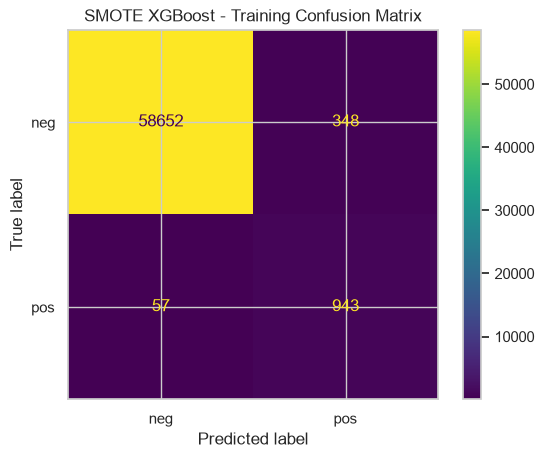

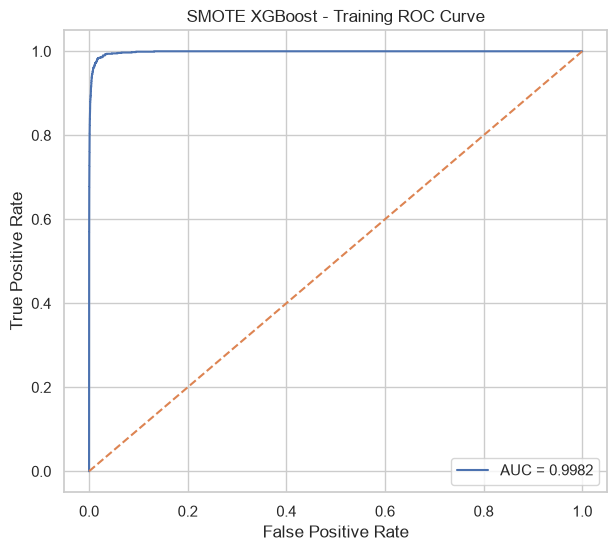

SMOTE XGBoost - Test Accuracy: 0.9899375
SMOTE XGBoost - Test Misclassification Error: 0.010062499999999974
SMOTE XGBoost - Test AUC: 0.9956553386666667

SMOTE XGBoost - Test Classification Report:
              precision    recall  f1-score   support

         neg       1.00      0.99      0.99     15625
         pos       0.74      0.88      0.80       375

    accuracy                           0.99     16000
   macro avg       0.87      0.93      0.90     16000
weighted avg       0.99      0.99      0.99     16000



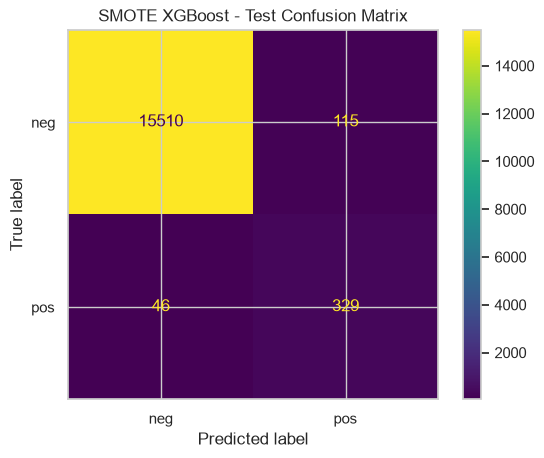

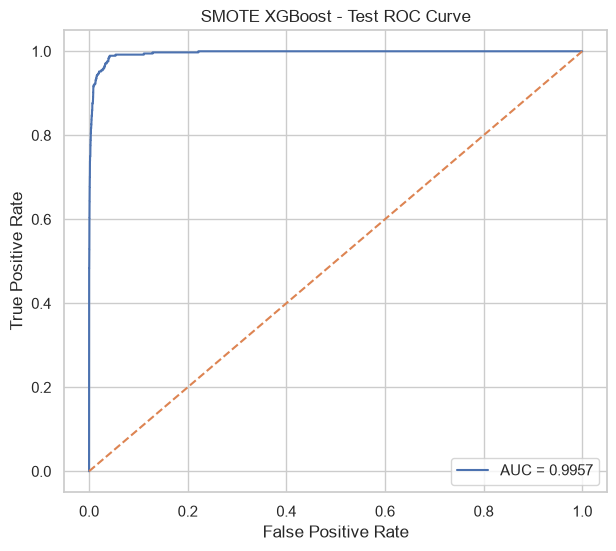

In [27]:
smote_train_results = (
    evaluate_binary_classifier(
        best_smote_xgb,
        X_train_raw,
        y_train,
        "SMOTE XGBoost - Training"
    )
)

smote_test_results = (
    evaluate_binary_classifier(
        best_smote_xgb,
        X_test_raw,
        y_test,
        "SMOTE XGBoost - Test"
    )
)

In [28]:
xgb_comparison = pd.DataFrame({
    "Model": [
        "XGBoost - No Compensation",
        "XGBoost + SMOTE"
    ],

    "Best Alpha": [
        best_xgb_alpha,
        best_smote_alpha
    ],

    "CV Error": [
        xgb_cv_error,
        smote_cv_error
    ],

    "Train Error": [
        xgb_train_results["error"],
        smote_train_results["error"]
    ],

    "Test Error": [
        xgb_test_results["error"],
        smote_test_results["error"]
    ],

    "Test AUC": [
        xgb_test_results["auc"],
        smote_test_results["auc"]
    ]
})

display(
    xgb_comparison
)

,Model,Best Alpha,CV Error,Train Error,Test Error,Test AUC
0,XGBoost - No Compensation,1,0.005667,0.001083,0.006125,0.996300
1,XGBoost + SMOTE,10,0.010467,0.006750,0.010062,0.995655


### 1(f) Comparison of XGBoost With and Without SMOTE

The uncompensated XGBoost model and the SMOTE-based XGBoost model produced the following results:

| Model | Best \(\alpha\) | CV Error | Train Error | Test Error | Test AUC |
|---|---:|---:|---:|---:|---:|
| XGBoost — No Compensation | 1 | 0.005667 | 0.001083 | 0.006125 | 0.996300 |
| XGBoost + SMOTE | 10 | 0.010467 | 0.006750 | 0.010062 | 0.995655 |

### Regularization Parameter

Cross-validation selected different L1 regularization parameters for the two models.

For the uncompensated XGBoost model,

\[
\alpha=1,
\]

whereas the SMOTE model selected

\[
\alpha=10.
\]

Thus, after SMOTE generated a much more balanced training set, cross-validation preferred substantially stronger L1 regularization.

This suggests that the oversampled training data required greater regularization to control model complexity.

---

### Cross-Validation Error

The uncompensated model has

\[
\text{CV Error}=0.005667,
\]

while the SMOTE model has

\[
\text{CV Error}=0.010467.
\]

Therefore, the cross-validation error is substantially higher after applying SMOTE.

The increase is approximately

\[
0.010467-0.005667
= 0.004800.
\]

Thus, based on cross-validation performance, the uncompensated XGBoost model performs better.

---

### Test Error

The uncompensated model achieves

\[
\text{Test Error}=0.006125,
\]

whereas the SMOTE model achieves

\[
\text{Test Error}=0.010062.
\]

Therefore,

\[
0.006125 < 0.010062,
\]

and the uncompensated model also performs better on the held-out test set.

The SMOTE model increases the test error by approximately

\[
0.010062-0.006125
= 0.003937.
\]

This corresponds to a noticeable deterioration in overall classification performance.

---

### ROC-AUC

The test AUC values are

\[
\text{AUC}_{\text{No Compensation}}
= 0.996300
\]

and

\[
\text{AUC}_{\text{SMOTE}}
= 0.995655.
\]

Both values are extremely high and indicate excellent discrimination between positive and negative observations.

However, the uncompensated XGBoost model still has a slightly higher AUC.

Thus, SMOTE does not improve the overall ranking ability of the classifier in this experiment.

---

### Training Error

The uncompensated model has a training error of

\[
0.001083,
\]

while the SMOTE model has a larger training error of

\[
0.006750.
\]

This is expected to some extent because SMOTE creates many synthetic minority-class observations, making the training problem more balanced and more difficult than the original highly imbalanced problem.

The stronger L1 regularization selected for the SMOTE model also contributes to a less exact fit of the training data.

---

### Effect of SMOTE

SMOTE was introduced to improve learning of the rare positive APS-failure class by creating synthetic minority observations.

However, in this experiment, SMOTE does not improve the overall predictive results.

Compared with the uncompensated model, the SMOTE model has:

- higher cross-validation error;
- higher training error;
- higher test error;
- slightly lower test AUC.

Therefore, based on the metrics reported in the comparison table, the uncompensated XGBoost classifier is superior.

However, the main purpose of SMOTE is often to improve minority-class detection rather than overall accuracy. Therefore, the confusion matrix and positive-class recall from the SMOTE model should also be considered.

If SMOTE substantially reduces false negatives or increases positive-class recall, then it may still provide a useful trade-off even though its overall test error is larger.

---

### Correct Cross-Validation Procedure

An important methodological point is that SMOTE was applied **inside the cross-validation pipeline**.

This is the correct procedure because synthetic observations were created only from the training portion of each fold.

Applying SMOTE before splitting the data into cross-validation folds would be incorrect because synthetic observations derived from validation examples could indirectly enter the corresponding training folds.

That would create data leakage and lead to an overly optimistic estimate of model performance.

Therefore, the cross-validation results reported here are based on the correct SMOTE procedure.

### Conclusion

In this experiment, the **uncompensated XGBoost model performs better overall** than XGBoost trained with SMOTE.

The uncompensated model achieves:

\[
\boxed{\text{CV Error}=0.005667}
\]

\[
\boxed{\text{Test Error}=0.006125}
\]

\[
\boxed{\text{Test AUC}=0.996300}
\]

compared with the SMOTE model:

\[
\boxed{\text{CV Error}=0.010467}
\]

\[
\boxed{\text{Test Error}=0.010062}
\]

\[
\boxed{\text{Test AUC}=0.995655}.
\]

Therefore, **SMOTE does not improve overall classification performance for this dataset under the selected XGBoost configuration**.

The uncompensated XGBoost model is the preferred model based on cross-validation error, test error, and ROC-AUC.

## 2. ISLR 6.6.3

The optimization problem is the constrained form of the LASSO:

\[
\min_{\beta_0,\beta_1,\ldots,\beta_p}
\sum_{i=1}^{n}
\left(
y_i-\beta_0-\sum_{j=1}^{p}\beta_jx_{ij}
\right)^2
\]

subject to

\[
\sum_{j=1}^{p}|\beta_j|\leq s.
\]

Increasing \(s\) relaxes the constraint and makes the model more
flexible.

### (a) Training RSS

**Answer: (iv) Steadily decrease.**

When \(s=0\), all slope coefficients must equal zero.

As \(s\) increases, the feasible set of coefficient values becomes
larger. A solution that was feasible for a smaller value of \(s\)
remains feasible for a larger value.

Therefore, minimizing RSS over an increasingly large feasible set
cannot increase the training RSS.

Thus the training RSS is non-increasing as \(s\) increases.

\[
\boxed{\text{(iv) Steadily decrease}}
\]

---

### (b) Test RSS

**Answer: (ii) Decrease initially and then eventually increase.**

For very small \(s\), the model is highly constrained and generally
has high bias, resulting in underfitting.

Increasing \(s\) initially improves the model and reduces test RSS.

However, if \(s\) becomes sufficiently large, the model becomes more
flexible and may overfit the training data. Its variance increases
and test RSS may begin to rise.

Therefore, test RSS generally follows a U-shaped curve.

\[
\boxed{\text{(ii) Decrease initially, then increase}}
\]

---

### (c) Variance

**Answer: (iii) Steadily increase.**

Increasing \(s\) reduces the amount of coefficient shrinkage and
allows the model to become more flexible.

More flexible models are more sensitive to the particular training
sample and therefore have higher variance.

\[
\boxed{\text{(iii) Steadily increase}}
\]

---

### (d) Squared Bias

**Answer: (iv) Steadily decrease.**

When \(s\) is small, the coefficients are heavily constrained toward
zero, so the model has relatively high bias.

As \(s\) increases, the model becomes more flexible and the bias
decreases.

\[
\boxed{\text{(iv) Steadily decrease}}
\]

---

### (e) Irreducible Error

**Answer: (v) Remain constant.**

The irreducible error is caused by the noise term in the true
data-generating process.

It does not depend on the statistical learning method or on the
value of \(s\).

\[
\boxed{\text{(v) Remain constant}}
\]

### Summary

| Part | Quantity | Answer |
|---|---|---|
| (a) | Training RSS | (iv) Steadily decrease |
| (b) | Test RSS | (ii) Decrease then increase |
| (c) | Variance | (iii) Steadily increase |
| (d) | Squared bias | (iv) Steadily decrease |
| (e) | Irreducible error | (v) Remain constant |

## 3. ISLR 6.6.5

We are given

\[
n=2,\qquad p=2,
\]

with

\[
x_{11}=x_{12},
\qquad
x_{21}=x_{22}.
\]

We also have

\[
y_1+y_2=0,
\]

\[
x_{11}+x_{21}=0,
\]

and

\[
x_{12}+x_{22}=0.
\]

Therefore, the intercept estimate is

\[
\hat{\beta}_0=0.
\]

### (a) Ridge Regression Optimization Problem

The ridge regression problem is

\[
\min_{\beta_1,\beta_2}
\left[
(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+
(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+
\lambda(\beta_1^2+\beta_2^2)
\right].
\]

Since

\[
x_{i1}=x_{i2},
\]

the fitted value for observation \(i\) depends on

\[
\beta_1+\beta_2.
\]

Therefore the objective can also be written as

\[
\sum_{i=1}^{2}
\left[
y_i-(\beta_1+\beta_2)x_{i1}
\right]^2
+
\lambda(\beta_1^2+\beta_2^2).
\]

---

### (b) Show that the Ridge Coefficients are Equal

The residual sum of squares depends only on the sum

\[
\beta_1+\beta_2.
\]

For any fixed value

\[
c=\beta_1+\beta_2,
\]

ridge regression minimizes

\[
\beta_1^2+\beta_2^2.
\]

Substituting

\[
\beta_2=c-\beta_1,
\]

the penalty becomes

\[
\beta_1^2+(c-\beta_1)^2.
\]

Differentiating with respect to \(\beta_1\),

\[
2\beta_1
-
2(c-\beta_1)
=0.
\]

Thus,

\[
4\beta_1=2c,
\]

so

\[
\beta_1=\frac{c}{2}.
\]

Therefore,

\[
\beta_2=\frac{c}{2},
\]

and hence

\[
\boxed{\hat{\beta}_1=\hat{\beta}_2}.
\]

Thus, ridge regression assigns equal coefficients to the two
perfectly correlated predictors.

---

### (c) LASSO Optimization Problem

The LASSO problem is

\[
\min_{\beta_1,\beta_2}
\left[
(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+
(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+
\lambda(|\beta_1|+|\beta_2|)
\right].
\]

Since the two predictors are identical, this becomes

\[
\min_{\beta_1,\beta_2}
\left[
\sum_{i=1}^{2}
\left(
y_i-(\beta_1+\beta_2)x_{i1}
\right)^2
+
\lambda(|\beta_1|+|\beta_2|)
\right].
\]

---

### (d) Why the LASSO Solution is Not Unique

Let

\[
c=\beta_1+\beta_2.
\]

The residual sum of squares depends only on \(c\).

Suppose the optimal value is \(c>0\). Any pair satisfying

\[
\beta_1\geq0,
\qquad
\beta_2\geq0,
\qquad
\beta_1+\beta_2=c
\]

has the same LASSO penalty because

\[
|\beta_1|+|\beta_2|
= \beta_1+\beta_2
= c.
\]

For example,

\[
(\beta_1,\beta_2)
= (c,0),
\]

\[
(\beta_1,\beta_2)
= \left(\frac{c}{2},\frac{c}{2}\right),
\]

and

\[
(\beta_1,\beta_2)
= (0,c)
\]

all produce the same fitted values and the same LASSO penalty.

Likewise, if \(c<0\), any pair with both coefficients non-positive
and summing to \(c\) produces the same objective value.

Therefore, there are infinitely many possible LASSO solutions.

\[
\boxed{\text{The LASSO coefficients are not unique.}}
\]

This illustrates why ridge regression tends to distribute coefficient
weight among correlated predictors, whereas LASSO may choose among
correlated predictors in a less stable way.

## 4. ISLR 8.4.5

The ten bootstrap estimates of

\[
P(\text{Class is Red}\mid X)
\]

are:

\[
0.10,\ 0.15,\ 0.20,\ 0.20,\ 0.55,\
0.60,\ 0.60,\ 0.65,\ 0.70,\ 0.75.
\]

### Majority-Vote Approach

Each individual classifier predicts Red when

\[
P(\text{Red}\mid X)>0.5.
\]

The first four probabilities are below 0.5, so they predict Green.

The remaining six probabilities are above 0.5, so they predict Red.

Therefore:

\[
\text{Red votes}=6,
\]

\[
\text{Green votes}=4.
\]

Using majority voting, the final prediction is

\[
\boxed{\text{Red}}.
\]

---

### Average-Probability Approach

The average predicted probability is

\[
\frac{
0.10+0.15+0.20+0.20+0.55+
0.60+0.60+0.65+0.70+0.75
}{10}.
\]

The sum is

\[
4.50,
\]

so

\[
\overline{P}(\text{Red}\mid X)
= \frac{4.50}{10}
= 0.45.
\]

Since

\[
0.45<0.5,
\]

the average-probability approach predicts

\[
\boxed{\text{Green}}.
\]

### Conclusion

The two aggregation procedures give different results:

| Method | Final Classification |
|---|---|
| Majority vote | Red |
| Average probability | Green |

The difference occurs because majority voting uses only the final
class prediction from each tree, while averaging probabilities also
takes the magnitude of each probability estimate into account.

## 5. ISLR 9.7.3

The observations are:

| Obs. | \(X_1\) | \(X_2\) | Class |
|---|---:|---:|---|
| 1 | 3 | 4 | Red |
| 2 | 2 | 2 | Red |
| 3 | 4 | 4 | Red |
| 4 | 1 | 4 | Red |
| 5 | 2 | 1 | Blue |
| 6 | 4 | 3 | Blue |
| 7 | 4 | 1 | Blue |

### (a) Sketch the Observations

The observations are plotted in the following code cell.

---

### (b) Optimal Separating Hyperplane

The maximal-margin separating hyperplane is

\[
1-2X_1+2X_2=0.
\]

Equivalently,

\[
X_2=X_1-\frac{1}{2}.
\]

---

### (c) Classification Rule

The maximal margin classifier can be written as

\[
f(X)
= \beta_0+\beta_1X_1+\beta_2X_2,
\]

where

\[
\beta_0=1,
\qquad
\beta_1=-2,
\qquad
\beta_2=2.
\]

Therefore,

\[
f(X)=1-2X_1+2X_2.
\]

The classification rule is:

\[
\boxed{
\text{Red if }
1-2X_1+2X_2>0
}
\]

and

\[
\boxed{
\text{Blue otherwise.}
}
\]

---

### (d) Margin

Using the scaling above, the two margin boundaries satisfy

\[
1-2X_1+2X_2=1
\]

and

\[
1-2X_1+2X_2=-1.
\]

These simplify to

\[
X_2=X_1
\]

and

\[
X_2=X_1-1.
\]

Therefore, the maximal-margin hyperplane lies exactly halfway between
these two lines:

\[
X_2=X_1-\frac12.
\]

The distance from the separating hyperplane to either margin is

\[
\frac{1}{\sqrt{(-2)^2+2^2}}
= \frac{1}{2\sqrt2}.
\]

---

### (e) Support Vectors

The observations lying on the margin are:

- Observation 2: \((2,2)\), Red
- Observation 3: \((4,4)\), Red
- Observation 5: \((2,1)\), Blue
- Observation 6: \((4,3)\), Blue

Therefore, the support vectors are

\[
\boxed{2,\ 3,\ 5,\ 6}.
\]

---

### (f) Movement of Observation 7

Observation 7 is

\[
(4,1),
\]

which lies well away from the separating hyperplane and is not a
support vector.

The maximal-margin classifier depends only on the support vectors.

Therefore, a slight movement of observation 7 would not affect the
maximal-margin hyperplane as long as the observation does not move
onto or inside the margin.

---

### (g) A Non-Optimal Separating Hyperplane

One separating hyperplane that correctly separates the classes but
does not maximize the margin is

\[
0.25-X_1+X_2=0.
\]

Equivalently,

\[
X_2=X_1-0.25.
\]

This correctly separates the red and blue observations but lies
closer to the red observations than the optimal hyperplane.

Therefore, it has a smaller margin and is not the maximal-margin
solution.

---

### (h) Add an Observation so Linear Separation is Impossible

Add a new **Blue** observation at

\[
(3,3).
\]

The point \((3,3)\) lies directly between two Red observations:

\[
(2,2)
\]

and

\[
(4,4).
\]

In fact,

\[
(3,3)
= \frac12(2,2) + \frac12(4,4).
\]

Therefore, the new Blue point lies inside the convex hull of the Red
class.

Once the convex hulls of the two classes overlap, no straight
hyperplane can perfectly separate the classes.

Thus, after adding the Blue point \((3,3)\), the data are no longer
linearly separable.

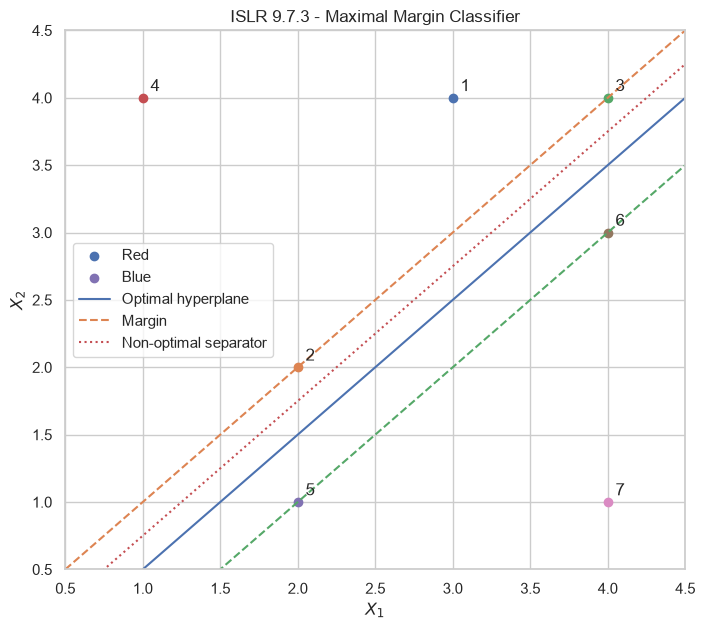

In [29]:
X_svm = np.array([
    [3, 4],
    [2, 2],
    [4, 4],
    [1, 4],
    [2, 1],
    [4, 3],
    [4, 1]
])

labels_svm = np.array([
    "Red",
    "Red",
    "Red",
    "Red",
    "Blue",
    "Blue",
    "Blue"
])

plt.figure(
    figsize=(8, 7)
)

for i, (
    point,
    label
) in enumerate(
    zip(
        X_svm,
        labels_svm
    ),
    start=1
):

    plt.scatter(
        point[0],
        point[1],
        label=(
            label
            if label not in labels_svm[:i-1]
            else None
        )
    )

    plt.text(
        point[0] + 0.05,
        point[1] + 0.05,
        str(i)
    )


x_values = np.linspace(
    0.5,
    4.5,
    200
)

# Optimal hyperplane
plt.plot(
    x_values,
    x_values - 0.5,
    label="Optimal hyperplane"
)

# Margin boundaries
plt.plot(
    x_values,
    x_values,
    linestyle="--",
    label="Margin"
)

plt.plot(
    x_values,
    x_values - 1,
    linestyle="--"
)

# Non-optimal separator
plt.plot(
    x_values,
    x_values - 0.25,
    linestyle=":",
    label="Non-optimal separator"
)

plt.xlim(
    0.5,
    4.5
)

plt.ylim(
    0.5,
    4.5
)

plt.xlabel("$X_1$")
plt.ylabel("$X_2$")

plt.title(
    "ISLR 9.7.3 - Maximal Margin Classifier"
)

plt.legend()
plt.grid(True)

plt.show()

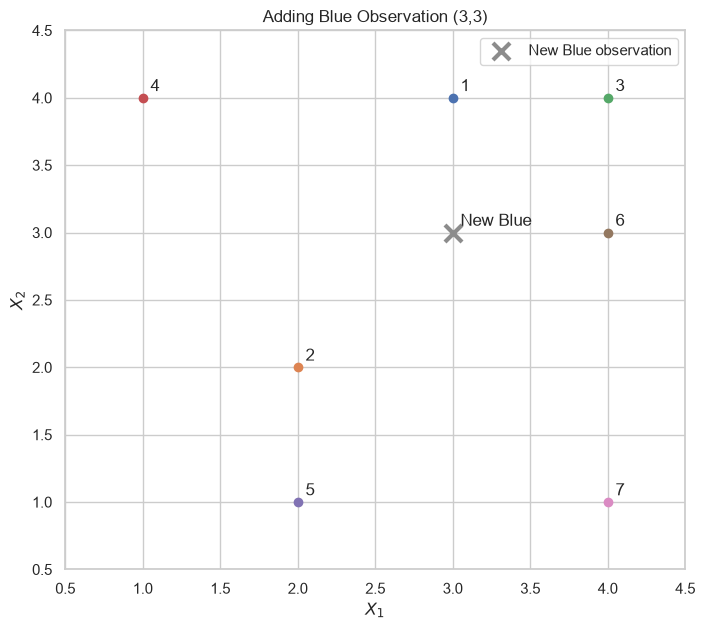

In [30]:
plt.figure(
    figsize=(8, 7)
)

for i, (
    point,
    label
) in enumerate(
    zip(
        X_svm,
        labels_svm
    ),
    start=1
):

    plt.scatter(
        point[0],
        point[1]
    )

    plt.text(
        point[0] + 0.05,
        point[1] + 0.05,
        str(i)
    )


# Additional blue observation
new_blue = np.array([
    3,
    3
])

plt.scatter(
    new_blue[0],
    new_blue[1],
    marker="x",
    s=150,
    linewidths=3,
    label="New Blue observation"
)

plt.text(
    new_blue[0] + 0.05,
    new_blue[1] + 0.05,
    "New Blue"
)

plt.xlabel("$X_1$")
plt.ylabel("$X_2$")

plt.title(
    "Adding Blue Observation (3,3)"
)

plt.xlim(
    0.5,
    4.5
)

plt.ylim(
    0.5,
    4.5
)

plt.legend()
plt.grid(True)

plt.show()